<div style="border-left:8px solid #EF3124;padding:6px 0 6px 22px">
<p style="color:#6F2BFE;font-weight:700;letter-spacing:1px">ФИНАНСОВЫЙ УНИВЕРСИТЕТ · ПРАКТИКА 02</p>
<h1>От финансовой таблицы<br>к исследованию данных</h1>
<p style="font-size:20px">Продолжаем pandas и готовим признаки клиента</p>
</div>

Начнём с повторения загрузки и отбора данных. Затем посчитаем расходы, сравним категории,
построим графики и подготовим таблицу с показателями клиентов.

### Перед началом

Откройте один из двух ноутбуков:

- `02_Практика_Pandas_EDA.ipynb` — с сохранёнными результатами примеров.
- `02_Практика_Pandas_EDA_без_результатов.ipynb` — тот же материал без выполненных ячеек.

Положите четыре CSV рядом с ноутбуком. В Google Colab загрузите их через панель «Файлы» в текущую папку.
Запускайте ячейки сверху вниз клавишами **Shift + Enter**. Задания выполняйте в ячейках «Ваш код».

Для локального запуска нужны pandas и matplotlib; установка описана в `README.txt`.

<a id="recap"></a>
## 0. Повторение: загрузка, просмотр и отбор строк

Вернёмся к `payments.csv`: **30 покупок, одна строка — одна покупка**.
Вспомним, как прочитать файл, выбрать столбцы, отсортировать таблицу и отобрать строки по условию.

| Поле | Смысл |
|---|---|
| `operation_id` | Идентификатор операции |
| `date` | Дата покупки; пока оставляем текстом |
| `category` | Категория покупки; есть пропуски |
| `channel` | Канал: «Карта» или «Онлайн» |
| `amount_rub` | Сумма покупки в рублях |
| `cashback_percent` | Ставка кэшбэка в процентах: 3 означает 3% |

In [1]:
import pandas as pd

payments = pd.read_csv("payments.csv")

print("Строк и столбцов:", payments.shape)
payments.head()

Строк и столбцов: (30, 6)


,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
1,1002,2026-10-01,Кафе,Карта,450,3
2,1003,2026-10-01,Транспорт,Карта,180,0
3,1004,2026-10-02,Аптеки,Карта,1350,1
4,1005,2026-10-02,Кафе,Онлайн,320,3


Одна пара скобок выбирает столбец; список внутри скобок — несколько столбцов.
`head(3)` показывает первые три строки, а `ascending=False` задаёт сортировку по убыванию.

In [2]:
payments[["operation_id", "category", "amount_rub"]].head(3)

,operation_id,category,amount_rub
0,1001,Супермаркеты,2450
1,1002,Кафе,450
2,1003,Транспорт,180


In [3]:
payments.sort_values("amount_rub", ascending=False).head(3)

,operation_id,date,category,channel,amount_rub,cashback_percent
11,1012,2026-10-04,Электроника,Онлайн,24000,1
20,1021,2026-10-07,Супермаркеты,Карта,5100,1
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1


Условие применяется **к каждой строке** и возвращает маску из `True` / `False`.
Таблица в квадратных скобках оставляет строки с `True`.

In [7]:
payments["amount_rub"].head()

0    2450
1     450
2     180
3    1350
4     320
Name: amount_rub, dtype: int64

In [4]:
is_large = payments["amount_rub"] > 1000

is_large.head()

0     True
1    False
2    False
3     True
4    False
Name: amount_rub, dtype: bool

In [8]:
payments[is_large].head()

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
3,1004,2026-10-02,Аптеки,Карта,1350,1
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1
6,1007,2026-10-03,Развлечения,Онлайн,1200,5
8,1009,2026-10-03,Супермаркеты,Карта,1750,1


### Задание. Повторение фильтра

Выберите из `payments` покупки **строго дороже 3 000 ₽**. Покажите отобранные строки и посчитайте их количество.

In [17]:
is_large = payments["amount_rub"] > 3000

int(payments[is_large]['operation_id'].count())

4

In [ ]:
# Ваш код:


**Проверка понимания:** `=` сохраняет значение, `==` сравнивает. Сортировка и фильтр сами по себе не меняют `payments`.
Если видите `NameError`, выполните ячейку, в которой создаётся нужная переменная.

<a id="filters"></a>
## 1. Фильтры: текст и несколько условий

### 1.1. Выбираем по тексту

Нужны покупки в кафе. Сравниваем столбец с текстом в кавычках через `==`.
Регистр и написание важны: «Кафе» и «кафе» — разные значения.

In [22]:
type(payments['category'].iloc[0])

str

In [18]:
is_cafe = payments["category"] == "Кафе"
payments[is_cafe]

,operation_id,date,category,channel,amount_rub,cashback_percent
1,1002,2026-10-01,Кафе,Карта,450,3
4,1005,2026-10-02,Кафе,Онлайн,320,3
9,1010,2026-10-04,Кафе,Карта,590,3
12,1013,2026-10-05,Кафе,Карта,410,3
17,1018,2026-10-06,Кафе,Карта,680,3
21,1022,2026-10-08,Кафе,Онлайн,350,3
27,1028,2026-10-10,Кафе,Карта,540,3


### 1.2. Два условия одновременно

Нужны покупки в кафе **не меньше 500 ₽**. `&` означает «и»: обе проверки должны быть истинны.
Сначала дадим условиям понятные имена.

In [26]:
is_cafe = payments["category"] == "Кафе"
at_least_500 = payments["amount_rub"] >= 500
payments[is_cafe | at_least_500]

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
1,1002,2026-10-01,Кафе,Карта,450,3
3,1004,2026-10-02,Аптеки,Карта,1350,1
4,1005,2026-10-02,Кафе,Онлайн,320,3
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1
6,1007,2026-10-03,Развлечения,Онлайн,1200,5
8,1009,2026-10-03,Супермаркеты,Карта,1750,1
9,1010,2026-10-04,Кафе,Карта,590,3
10,1011,2026-10-04,Аптеки,Онлайн,860,1
11,1012,2026-10-04,Электроника,Онлайн,24000,1


Ожидаем три операции: **1010, 1018, 1028**.

Короткая запись: `payments[(payments["category"] == "Кафе") & (payments["amount_rub"] >= 500)]`.
Скобки вокруг сравнений обязательны. Для целых столбцов используем `&`, а не Python `and`.

**Устно:** попадёт ли сюда покупка на 500 ₽? А при условии `> 500`?

### 
Задание 1. Онлайн-покупки от 2 000 ₽

Выберите канал `"Онлайн"` и сумму **от 2 000 ₽ включительно**. Сохраните результат в `online_2000`, покажите строки и их число.

In [27]:
payments.head()

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
1,1002,2026-10-01,Кафе,Карта,450,3
2,1003,2026-10-01,Транспорт,Карта,180,0
3,1004,2026-10-02,Аптеки,Карта,1350,1
4,1005,2026-10-02,Кафе,Онлайн,320,3


In [30]:
# Ваш код: задание 1
is_online = payments["channel"] == "Онлайн"

amount_2000 = payments["amount_rub"] >= 2000

online_2000 = payments[is_online & amount_2000]
online_2000

,operation_id,date,category,channel,amount_rub,cashback_percent
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1
11,1012,2026-10-04,Электроника,Онлайн,24000,1
14,1015,2026-10-05,Супермаркеты,Онлайн,2950,1
28,1029,2026-10-10,Супермаркеты,Онлайн,3250,1
29,1030,2026-10-10,Развлечения,Онлайн,2200,5


<a id="missing"></a>
## 2. Пропуск — это тоже информация

У двух операций нет категории. pandas отображает отсутствие значения как `NaN` или `<NA>`.
**Неизвестная категория не означает отсутствие расхода.**

`isna()` проверяет пропуски, `sum()` считает ответы `True` отдельно по столбцам.

In [31]:
payments.isna()

,operation_id,date,category,channel,amount_rub,cashback_percent
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
5,False,False,False,False,False,False
6,False,False,False,False,False,False
7,False,False,False,False,False,False
8,False,False,False,False,False,False
9,False,False,False,False,False,False


In [32]:
payments.isna().sum()

operation_id        0
date                0
category            2
channel             0
amount_rub          0
cashback_percent    0
dtype: int64

In [33]:
payments[payments["category"].isna()]

,operation_id,date,category,channel,amount_rub,cashback_percent
15,1016,2026-10-06,NaN,Карта,720,0
22,1023,2026-10-08,NaN,Онлайн,1600,0


Это операции **1016 и 1023**, на **720 и 1 600 ₽**. Суммы известны; удалять строки из отчёта о расходах не следует.
Для отчёта обозначим неизвестную категорию текстом **«Без категории»**. Это не попытка угадать покупку.

In [35]:
payments["category"].fillna("Без категории")

0      Супермаркеты
1              Кафе
2         Транспорт
3            Аптеки
4              Кафе
5      Супермаркеты
6       Развлечения
7         Транспорт
8      Супермаркеты
9              Кафе
10           Аптеки
11      Электроника
12             Кафе
13        Транспорт
14     Супермаркеты
15    Без категории
16      Развлечения
17             Кафе
18           Аптеки
19        Транспорт
20     Супермаркеты
21             Кафе
22    Без категории
23      Развлечения
24     Супермаркеты
25        Транспорт
26           Аптеки
27             Кафе
28     Супермаркеты
29      Развлечения
Name: category, dtype: object

In [34]:
payments["category"] = payments["category"].fillna("Без категории")
print("Пропусков категории:", payments["category"].isna().sum())

Пропусков категории: 0


Присваивание обновляет столбец в памяти. Исходный CSV остаётся прежним.
Повторное выполнение `fillna` не меняет уже заполненные значения.

Почему отсутствующую категорию можно обозначить текстом, а отсутствующий доход нельзя автоматически заменить нулём?
Различайте «значение равно нулю» и «значение неизвестно».

<a id="metrics"></a>
## 3. Считаем показатели и сравниваем группы

### 3.1. Сумма, среднее и медиана

`sum()` складывает, `mean()` считает среднее, `median()` — середину упорядоченного ряда.
Для чётного количества значений медиана — среднее двух центральных.
`round(..., 2)` округляет отображаемое число до двух знаков.

In [36]:
payments.head()

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
1,1002,2026-10-01,Кафе,Карта,450,3
2,1003,2026-10-01,Транспорт,Карта,180,0
3,1004,2026-10-02,Аптеки,Карта,1350,1
4,1005,2026-10-02,Кафе,Онлайн,320,3


In [37]:
total = payments["amount_rub"].sum()
average = payments["amount_rub"].mean()
median = payments["amount_rub"].median()

print("Всего:", total, "₽")
print("Средняя покупка:", round(average, 2), "₽")
print("Медианная покупка:", median, "₽")

Всего: 62880 ₽
Средняя покупка: 2096.0 ₽
Медианная покупка: 1035.0 ₽


Получилось **62 880 ₽**, среднее **2 096 ₽**, медиана **1 035 ₽**.
Покупка электроники за 24 000 ₽ заметно повышает среднее.
Поэтому перед выводом об обычном размере покупки полезно посмотреть оба показателя.
Эти значения описывают расходы в рассматриваемой таблице.

### 3.2. Частота и сумма — разные вещи

`value_counts()` считает, сколько раз встретилась каждая категория.

In [38]:
payments["category"].value_counts()

category
Супермаркеты     7
Кафе             7
Транспорт        5
Аптеки           4
Развлечения      4
Без категории    2
Электроника      1
Name: count, dtype: int64

В кафе и супермаркетах по **7 покупок**. Где денег больше? Нужна другая операция.

`groupby("category")` разбивает строки на группы. Затем берём суммы покупок и складываем внутри каждой группы.

In [39]:
spending_by_category = payments.groupby("category")["amount_rub"].sum()

In [40]:
spending_by_category

category
Аптеки            4820
Без категории     2320
Кафе              3340
Развлечения       6150
Супермаркеты     21280
Транспорт          970
Электроника      24000
Name: amount_rub, dtype: int64

In [41]:
spending_by_category = payments.groupby("category")["amount_rub"].sum()
spending_by_category.sort_values(ascending=False)

category
Электроника      24000
Супермаркеты     21280
Развлечения       6150
Аптеки            4820
Кафе              3340
Без категории     2320
Транспорт          970
Name: amount_rub, dtype: int64

Читаем слева направо: **собрать категории → взять `amount_rub` → сложить в каждой категории**.

По сумме лидирует электроника — **24 000 ₽ от одной покупки**. «Без категории» тоже учтено — **2 320 ₽**.
Если группировать по исходной категории с пропусками, pandas по умолчанию не включит пустые группы.
Явная подпись помогла сохранить все расходы в разрезе категорий.

In [ ]:
print("Всего по исходным строкам:", payments["amount_rub"].sum())
print("Всего по группам:", spending_by_category.sum())

### Задание 2. Короткий отчёт по аптекам

Отберите категорию `"Аптеки"` в `pharmacy`. Посчитайте число покупок и сумму расходов.

In [65]:
payments[payments["category"] == "Аптеки"]['operation_id'].nunique()

4

In [66]:
payments[payments["category"] == "Аптеки"]["amount_rub"].sum()

np.int64(4820)

In [51]:
spending_by_category = payments.groupby('category').value_counts('Аптеки')

ValueError: Keys {'е', 'и', 'п', 'А', 'т', 'к'} in subset do not exist in the DataFrame.

In [60]:
spending_by_category['Аптеки']

operation_id  date        channel  amount_rub  cashback_percent
1004          2026-10-02  Карта    1350        1                   1
1011          2026-10-04  Онлайн   860         1                   1
1019          2026-10-07  Карта    1490        1                   1
1027          2026-10-09  Онлайн   1120        1                   1
Name: count, dtype: int64

In [59]:
spending_by_category['Аптеки'].loc['amount_rub']

KeyError: 'amount_rub'

In [54]:
spending_by_category['Аптеки']['amount_rub'].sum()

KeyError: 'amount_rub'

In [42]:
payments

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
1,1002,2026-10-01,Кафе,Карта,450,3
2,1003,2026-10-01,Транспорт,Карта,180,0
3,1004,2026-10-02,Аптеки,Карта,1350,1
4,1005,2026-10-02,Кафе,Онлайн,320,3
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1
6,1007,2026-10-03,Развлечения,Онлайн,1200,5
7,1008,2026-10-03,Транспорт,Карта,210,0
8,1009,2026-10-03,Супермаркеты,Карта,1750,1
9,1010,2026-10-04,Кафе,Карта,590,3


In [ ]:
# Ваш код: задание 2


<a id="chart"></a>
## 4. Сравниваем расходы на графике

Горизонтальная столбчатая диаграмма удобна для длинных названий категорий.
Длина столбика показывает **сумму расходов**, а не количество покупок.

Для построения графика подключим `matplotlib.pyplot` под коротким именем `plt`.
`plot.barh()` рисует горизонтальные столбики, а команды `plt` задают заголовок и подписи.

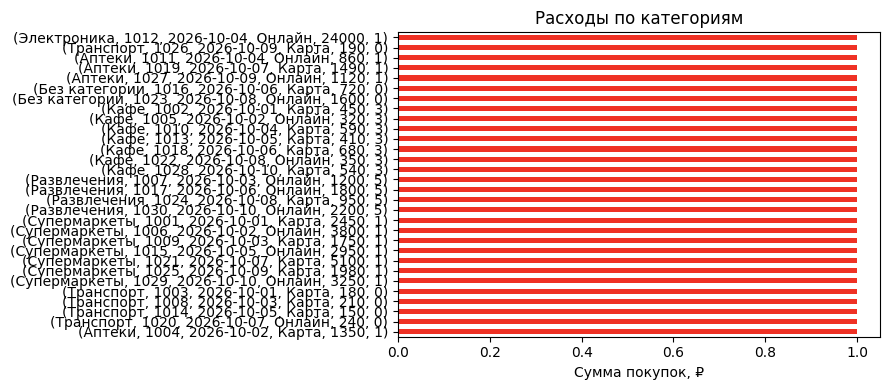

In [67]:
import matplotlib.pyplot as plt

spending_by_category.sort_values().plot.barh(color="#EF3124", figsize=(9, 4))
plt.title("Расходы по категориям")
plt.xlabel("Сумма покупок, ₽")
plt.ylabel("")
plt.tight_layout()
plt.show()

**На минуту станьте редактором графика:**

- Есть ли единицы измерения и понятная подпись показателя?
- Какая одна операция сильнее всего влияет на картину?
- Что изменится, если построить число покупок вместо суммы?

Не называйте электронику «самой популярной категорией»: график показывает деньги.
Чтобы объяснить столбик, вернитесь к исходным строкам через фильтр.

<a id="report"></a>
## 5. Новый столбец и самостоятельный отчёт

### 5.1. Кэшбэк в рублях

Кэшбэк рассчитываем по формуле: **сумма × ставка / 100**. Для 450 ₽ и 3% это 13,50 ₽.
Умножение столбцов выполнится построчно. Результат запишем в новый столбец `cashback_rub`.
В этой задаче округляем каждую операцию до копеек.

In [68]:
payments["cashback_rub"] = (
    payments["amount_rub"] * payments["cashback_percent"] / 100
).round(2)
payments[["operation_id", "amount_rub", "cashback_percent", "cashback_rub"]].head()

,operation_id,amount_rub,cashback_percent,cashback_rub
0,1001,2450,1,24.5
1,1002,450,3,13.5
2,1003,180,0,0.0
3,1004,1350,1,13.5
4,1005,320,3,9.6


In [69]:
payments["cashback_rub"]

0      24.5
1      13.5
2       0.0
3      13.5
4       9.6
5      38.0
6      60.0
7       0.0
8      17.5
9      17.7
10      8.6
11    240.0
12     12.3
13      0.0
14     29.5
15      0.0
16     90.0
17     20.4
18     14.9
19      0.0
20     51.0
21     10.5
22      0.0
23     47.5
24     19.8
25      0.0
26     11.2
27     16.2
28     32.5
29    110.0
Name: cashback_rub, dtype: float64

Появилось **30 значений**, а не один итог. pandas перемножает значения из одной строки:
сумму первой покупки — на её ставку, сумму второй — на её ставку и так далее.

### Задание 3. Проверяем кэшбэк

Посчитайте общий кэшбэк и покажите операцию с самым большим кэшбэком.

In [ ]:
# Ваш код: задание 3


### Задание 4. Отчёт об онлайн-покупках

Подготовьте отчёт только о канале `"Онлайн"`:

1. Сохраните строки в `online_report`.
2. Посчитайте число покупок и общую сумму.
3. Покажите крупнейшую покупку.
4. В следующей текстовой ячейке напишите **одно предложение с числами, единицами и границей вывода**.

In [73]:
payments[payments["channel"] == "Онлайн"]["operation_id"].nunique()

13

In [74]:
payments[payments["channel"] == "Онлайн"]["amount_rub"].sum()

np.int64(43690)

In [77]:
payments[payments["channel"] == "Онлайн"]

,operation_id,date,category,channel,amount_rub,cashback_percent,cashback_rub
4,1005,2026-10-02,Кафе,Онлайн,320,3,9.6
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1,38.0
6,1007,2026-10-03,Развлечения,Онлайн,1200,5,60.0
10,1011,2026-10-04,Аптеки,Онлайн,860,1,8.6
11,1012,2026-10-04,Электроника,Онлайн,24000,1,240.0
14,1015,2026-10-05,Супермаркеты,Онлайн,2950,1,29.5
16,1017,2026-10-06,Развлечения,Онлайн,1800,5,90.0
19,1020,2026-10-07,Транспорт,Онлайн,240,0,0.0
21,1022,2026-10-08,Кафе,Онлайн,350,3,10.5
22,1023,2026-10-08,Без категории,Онлайн,1600,0,0.0


In [79]:
payments[payments["channel"] == "Онлайн"].sort_values(by="amount_rub", ascending=False).head(1)

,operation_id,date,category,channel,amount_rub,cashback_percent,cashback_rub
11,1012,2026-10-04,Электроника,Онлайн,24000,1,240.0


In [ ]:
# Ваш код: задание 4


**Мой вывод:** замените этот текст своим предложением.

Двойной щелчок открывает текстовую ячейку для редактирования. **Shift + Enter** завершает редактирование.

### 5.2. Сохраняем результат

Сохраним **все 30 покупок** с заполненной категорией и рассчитанным кэшбэком.
`index=False` не записывает служебный индекс; `utf-8-sig` помогает Excel прочитать русский текст.

In [80]:
payments.to_csv("payments_result.csv", index=False, encoding="utf-8-sig")
print("Сохранён payments_result.csv:", payments.shape)

Сохранён payments_result.csv: (30, 7)


Файл содержит **30 строк и 7 столбцов**. Его можно открыть в Excel; в Colab — скачать через панель «Файлы».
Исходный `payments.csv` не изменился. Повторный запуск обновляет только `payments_result.csv`.

<a id="eda"></a>
## 6. Правда ли покупок стало меньше?

В отчёте по карте показаны четыре недели. В последней — 51 тысяча покупок против 101 тысячи ранее.
При этом последняя неделя наблюдалась только **3,5 дня**.

Посмотрим на отчёт и проверим, что именно изменилось.
Такую работу называют **EDA — исследовательским анализом данных**: формулируем вопросы,
сравниваем показатели и проверяем возможные объяснения.

In [81]:
weekly = pd.read_csv("weekly_purchases.csv")
weekly

,week,purchases,observed_days
0,4–10 мая,100000,7.0
1,11–17 мая,98000,7.0
2,18–24 мая,101000,7.0
3,25–31 мая,51000,3.5


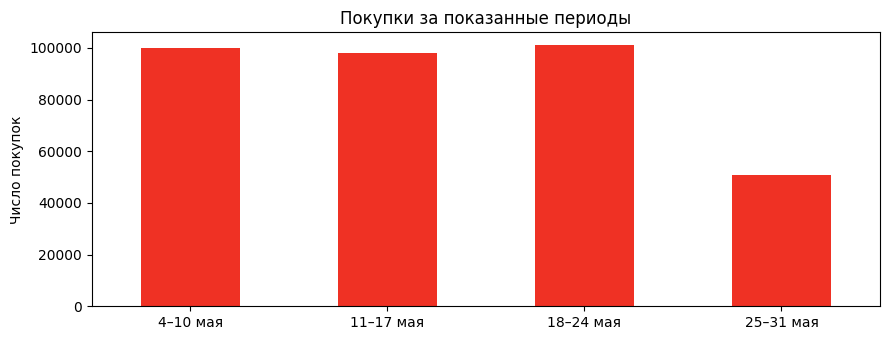

In [82]:
weekly.plot.bar(x="week", y="purchases", legend=False, color="#EF3124", figsize=(9, 3.5))
plt.title("Покупки за показанные периоды")
plt.xlabel("")
plt.ylabel("Число покупок")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**До следующей ячейки:** можно ли уже утверждать, что клиенты уходят? Назовите две проверки.

Первой проверкой сделаем сопоставимость длительности. Разделим число покупок на число наблюдавшихся дней.

In [83]:
weekly["purchases_per_day"] = weekly["purchases"] / weekly["observed_days"]
weekly[["week", "purchases", "observed_days", "purchases_per_day"]].round(2)

,week,purchases,observed_days,purchases_per_day
0,4–10 мая,100000,7.0,14285.71
1,11–17 мая,98000,7.0,14000.00
2,18–24 мая,101000,7.0,14428.57
3,25–31 мая,51000,3.5,14571.43


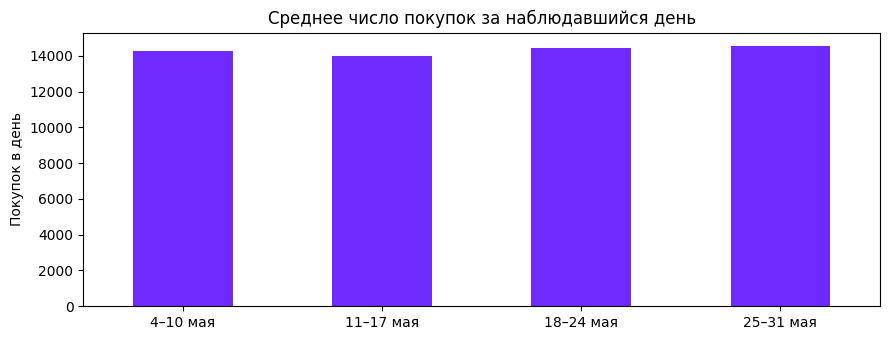

In [84]:
weekly.plot.bar(x="week", y="purchases_per_day", legend=False, color="#6F2BFE", figsize=(9, 3.5))
plt.title("Среднее число покупок за наблюдавшийся день")
plt.xlabel("")
plt.ylabel("Покупок в день")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

В последнем периоде около **14 571 покупки в день**, в предыдущем — **14 429**.
По этому сравнению падения почти вдвое не видно.
Но деление на дни не учитывает различия между буднями и выходными и временем суток.
Для более строгой проверки нужны одинаковые завершённые периоды или сопоставимые дни и часы.

**Вывод из проверки:** сравнение сырых итогов было несопоставимым. Причину изменения поведения клиентов мы пока не установили.

Что ещё проверить:

- Полноту выгрузки и изменение кодов успешной покупки.
- Предыдущие месяцы, аналогичные недели прошлого года и сезонность.
- Нули по дням и возможные технические сбои.
- Число уникальных покупателей и частоту покупок у одного покупателя.

Совпадение спада с акцией конкурента само по себе не доказывает причину.

### Задание 5. Сформулируйте проверку гипотезы

Запишите ответ в текстовой ячейке ниже:

1. Что можно утверждать по двум графикам?
2. Назовите ещё одну гипотезу и данные для её проверки.
3. Почему в `payments.csv` нельзя посчитать уникальных покупателей?

Код в этом задании необязателен.

In [ ]:
# Ваш код: задание 5


**Мой ответ:**

1. По графикам можно сказать: …
2. Проверю гипотезу … с помощью …
3. Покупателей в `payments.csv` не посчитать, потому что …

<a id="clients"></a>
## 7. От операций к признакам клиента

До этого **одна строка соответствовала покупке**. Теперь хотим получить таблицу,
в которой **одна строка соответствует клиенту**, а столбцы описывают его покупки за май.

Дата прогноза — **1 июня 2026, 00:00**. По информации, доступной к этому моменту,
хотим определить, кто из активных клиентов перестанет покупать в июне.

| Элемент задачи | Определение |
|---|---|
| Объект | Клиент на дату среза 1 июня |
| Признаки | Сведения о покупках мая, доступные до даты среза |
| Target | `target_churn_june = 1`, если в июне нет проведённых покупок; иначе 0 |
| Аудитория | Клиенты, покупавшие в мае |

Отсутствие покупок по карте — наше определение неактивности; оно не означает закрытие всех отношений с банком.
Июнь уже завершился, поэтому будущие относительно среза исходы известны.
Target взят из полной разметки за июнь. Файл операций ниже содержит только часть июньских событий:
по нему нельзя заново рассчитать target.

### 7.1. Знакомимся с двумя таблицами

В первом файле — операции, во втором — сведения о клиентах.
Общий столбец `client_id` позволяет определить, какому клиенту принадлежит операция.

| Файл / поле | Что означает |
|---|---|
| `transactions_churn.csv` | Выгрузка проведённых покупок |
| `transaction_id` | ID покупки |
| `event_at` | Когда произошла покупка |
| `available_at` | Когда запись стала доступна аналитической системе |
| `category`, `amount_rub` | Категория и сумма покупки |
| `clients_churn.csv` | Реестр клиентов: ID, тип карты, полнота истории и target |
| `history_complete` | Вся история, доступная на дату среза, загружена без потерь |

Время в обоих полях указано в одной временной зоне. Рассматриваем проведённые покупки без отмен и возвратов.

**Таблица операций `transactions`:** один клиент может встречаться в нескольких строках.

In [85]:
transactions = pd.read_csv("transactions_churn.csv")
transactions

,transaction_id,client_id,event_at,available_at,category,amount_rub
0,T501,C001,2026-05-10 12:00,2026-05-10 12:01,Продукты,1500
1,T502,C002,2026-05-12 09:00,2026-05-12 09:01,Кафе,700
2,T503,C001,2026-05-15 18:00,2026-05-15 18:01,Кафе,500
3,T504,C001,2026-05-28 08:00,2026-05-28 08:01,Транспорт,1000
4,T505,C002,2026-05-29 15:00,2026-05-29 15:01,Продукты,300
5,T506,C001,2026-05-30 10:00,2026-05-30 10:01,Продукты,1000
6,T506,C001,2026-05-30 10:00,2026-05-30 10:01,Продукты,1000
7,T507,C002,2026-05-31 23:58,2026-06-02 09:00,Кафе,200
8,T508,C001,2026-06-05 12:00,2026-06-05 12:01,Продукты,900


**Реестр клиентов `clients`:** каждому клиенту соответствует одна строка.

In [86]:
clients = pd.read_csv("clients_churn.csv")
clients

,client_id,card_type,history_complete,target_churn_june
0,C001,Дебетовая,True,0
1,C002,Кредитная,True,1
2,C003,Дебетовая,True,1


### 7.2. Дубликат или другая покупка?

Одинаковые суммы не делают операции дубликатами. Сначала разберитесь с ключом и версиями записи.
В этом файле `T506` загружена дважды без каких-либо отличий.
`duplicated()` отмечает повторные **полностью одинаковые** строки; `drop_duplicates()` оставляет первую копию.

In [89]:
transactions.duplicated(keep=False)

0    False
1    False
2    False
3    False
4    False
5     True
6     True
7    False
8    False
dtype: bool

In [87]:
print("Полностью повторных строк:", transactions.duplicated().sum())
transactions[transactions.duplicated(keep=False)]

Полностью повторных строк: 1


,transaction_id,client_id,event_at,available_at,category,amount_rub
5,T506,C001,2026-05-30 10:00,2026-05-30 10:01,Продукты,1000
6,T506,C001,2026-05-30 10:00,2026-05-30 10:01,Продукты,1000


In [90]:
transactions_unique = transactions.drop_duplicates().copy()
print("После удаления полных повторов:", len(transactions_unique))
print("ID покупок уникальны:", transactions_unique["transaction_id"].is_unique)

После удаления полных повторов: 8
ID покупок уникальны: True


Осталось **8 строк**. Если один ID имел бы разные версии или статусы, простого удаления одинаковых строк было бы недостаточно:
понадобилось бы правило выбора корректного состояния на дату среза. Не удаляйте разные покупки только по сумме или ID клиента.

### 7.3. Что было доступно на дату прогноза?

`pd.to_datetime` превращает текст в дату-время. Теперь даты можно корректно сравнивать.
Признаки считаем за интервал **[1 мая, 1 июня)**: начало включено, конец не включён.
Дополнительно запись должна быть доступна **строго до** 1 июня 00:00.

In [91]:
transactions_unique["event_at"] = pd.to_datetime(transactions_unique["event_at"])
transactions_unique["available_at"] = pd.to_datetime(transactions_unique["available_at"])

In [92]:
transactions_unique["event_at"] = pd.to_datetime(transactions_unique["event_at"])
transactions_unique["available_at"] = pd.to_datetime(transactions_unique["available_at"])

window_start = pd.Timestamp("2026-05-01 00:00")
cutoff = pd.Timestamp("2026-06-01 00:00")

is_may = (transactions_unique["event_at"] >= window_start) & (transactions_unique["event_at"] < cutoff)
was_available = transactions_unique["available_at"] < cutoff
history = transactions_unique[is_may & was_available].copy()
history

,transaction_id,client_id,event_at,available_at,category,amount_rub
0,T501,C001,2026-05-10 12:00:00,2026-05-10 12:01:00,Продукты,1500
1,T502,C002,2026-05-12 09:00:00,2026-05-12 09:01:00,Кафе,700
2,T503,C001,2026-05-15 18:00:00,2026-05-15 18:01:00,Кафе,500
3,T504,C001,2026-05-28 08:00:00,2026-05-28 08:01:00,Транспорт,1000
4,T505,C002,2026-05-29 15:00:00,2026-05-29 15:01:00,Продукты,300
5,T506,C001,2026-05-30 10:00:00,2026-05-30 10:01:00,Продукты,1000


Остались **6 операций**, доступных до среза.

- `T507` произошла 31 мая, но поступила только 2 июня. На дату прогноза её ещё не было.
- `T508` произошла в июне: это будущее относительно среза.

Если включить их в майские признаки обучения, получится **утечка (leakage)**: на реальном прогнозе такие сведения недоступны.
При этом полная разметка target за июнь по определению использует будущий исход — это допустимо для обучения.
Её нельзя включать в признаки.

### 7.4. Проверяем покупателей и частоту

`nunique()` считает уникальные значения. Один клиент может иметь несколько покупок,
поэтому количество операций и число клиентов не совпадают.

In [93]:
buyers = history["client_id"].nunique()
print("Покупок:", len(history))
print("Покупателей:", buyers)
print("Покупок на покупателя:", len(history) / buyers)

Покупок: 6
Покупателей: 2
Покупок на покупателя: 3.0


Получилось **6 = 2 × 3**: покупки = покупатели × среднее число покупок на покупателя.
Это тождество для одного и того же набора успешных покупок. Сравнение одинаковых периодов помогло бы понять,
какая из двух составляющих изменилась.

### 7.5. Группируем по клиенту

Раньше группировали расходы по категории. Теперь группируем по `client_id`.
`agg` позволяет одновременно посчитать несколько показателей и дать результатам имена.

In [94]:
history

,transaction_id,client_id,event_at,available_at,category,amount_rub
0,T501,C001,2026-05-10 12:00:00,2026-05-10 12:01:00,Продукты,1500
1,T502,C002,2026-05-12 09:00:00,2026-05-12 09:01:00,Кафе,700
2,T503,C001,2026-05-15 18:00:00,2026-05-15 18:01:00,Кафе,500
3,T504,C001,2026-05-28 08:00:00,2026-05-28 08:01:00,Транспорт,1000
4,T505,C002,2026-05-29 15:00:00,2026-05-29 15:01:00,Продукты,300
5,T506,C001,2026-05-30 10:00:00,2026-05-30 10:01:00,Продукты,1000


In [ ]:
history.groupby('client_id').agg(
    max_

In [95]:
features = history.groupby("client_id").agg(
    purchase_count=("transaction_id", "count"),
    amount_sum_rub=("amount_rub", "sum"),
).reset_index()
features

,client_id,purchase_count,amount_sum_rub
0,C001,4,4000
1,C002,2,1000


В `purchase_count` считаем непустые ID операций; здесь они все заполнены и уникальны.
`reset_index()` возвращает ID клиента из индекса в обычный столбец.

У `C001` четыре покупки на 4 000 ₽, у `C002` — две на 1 000 ₽.
Клиента `C003` в `features` нет, потому что в отобранной истории нет его покупок.

### 7.6. Объединяем сведения о клиенте и его покупках

У нас есть две части информации:

- В `clients` — **кто клиент**: его ID, тип карты, полнота истории и target.
- В `features` — **как он покупал в мае**: количество покупок и их общая сумма.

Хотим собрать их в одной строке. Например, рядом с данными клиента `C001`
должны появиться **4 покупки** и **4 000 ₽**.

#### Сначала посмотрим на левую таблицу — `clients`

Берём её за основу: в результате хотим сохранить каждого из этих трёх клиентов.
Количество покупок и сумму к ним ещё предстоит добавить.

In [ ]:
clients

#### Теперь правая таблица — `features`

Отсюда возьмём два новых столбца: `purchase_count` и `amount_sum_rub`.
В этой таблице только два клиента: `C001` и `C002`.

In [ ]:
features

#### Как понять, какую строку с какой соединить?

В обеих таблицах есть `client_id`. Одинаковый ID означает одного и того же клиента.
Это и есть **ключ объединения**.

Для каждой строки из `clients` ищем строку с таким же `client_id` в `features`:

| Берём клиента из `clients` | Ищем в `features` | Что добавляем |
|---|---|---|
| `C001` | Строку с `client_id = C001` | 4 покупки, 4 000 ₽ |
| `C002` | Строку с `client_id = C002` | 2 покупки, 1 000 ₽ |
| `C003` | Строки с таким ID нет | Пока пропуски в обоих новых столбцах |

**Сопоставляем ID, а не позиции строк.** Если поменять строки в правой таблице местами,
`C001` всё равно получит свои 4 покупки, а не показатели другого клиента.

#### Выполняем объединение

Метод `merge()` ищет эти совпадения и добавляет столбцы из правой таблицы к левой.

In [ ]:
client_table = clients.merge(
    features,
    on="client_id",
    how="left",
    validate="one_to_one",
)
client_table

Разберём запись:

| Часть команды | Что она означает |
|---|---|
| `clients.merge(...)` | Начинаем с таблицы клиентов — она слева |
| `features` | Добавляем показатели из этой таблицы — она справа |
| `on="client_id"` | Ищем совпадения по ID клиента |
| `how="left"` | Сохраняем все строки левой таблицы, даже без совпадения справа |
| `validate="one_to_one"` | Проверяем, что каждому ID соответствует не больше одной строки в каждой таблице |

В результате **по-прежнему три клиента**. Сведения из `clients` сохранились,
справа появились количество покупок и сумма. Общий `client_id` не продублировался.

**Почему выбрали `left`?** Клиент `C003` есть в реестре, но не представлен в покупках.
Он должен остаться в результате, чтобы мы могли разобраться с отсутствующими показателями.
Если сохранить только найденные совпадения, `C003` исчезнет из таблицы.

#### Почему у `C003` стоят `NaN`, а не нули?

`merge()` умеет найти совпадение, но не знает, почему его нет.
Поэтому он ставит пропуски. Они означают: «для этого ID не нашлось строки справа».

Сначала проверяем полноту истории. При `history_complete = True` знаем,
что доступная на дату среза история загружена без потерь. Поэтому отсутствие покупок в ней
можно записать как **0 покупок и 0 ₽**. При неполной загрузке так делать нельзя.

In [ ]:
if not client_table["history_complete"].all():
    raise ValueError("Сначала проверьте полноту истории: пропуски нельзя автоматически заменить нулём")

client_table["purchase_count"] = client_table["purchase_count"].fillna(0).astype(int)
client_table["amount_sum_rub"] = client_table["amount_sum_rub"].fillna(0)
client_table

### 7.7. Выбираем аудиторию и отделяем target

Мы сохранили всех клиентов при объединении. Теперь применим условие задачи:
нужны те, кто ещё покупал в мае и может перестать покупать в июне.
Оставим строки с `purchase_count > 0`. Клиент `C003` этому условию не соответствует.

Создадим **X** — таблицу признаков, и **y** — столбец будущих исходов.
`client_id` оставим в индексе, чтобы сопоставлять строки. Target в X не включаем.

**X — признаки, известные на дату прогноза:**

In [ ]:
active_clients = client_table[client_table["purchase_count"] > 0].copy()
active_clients = active_clients.set_index("client_id")

X = active_clients[["purchase_count", "amount_sum_rub", "card_type"]].copy()
y = active_clients["target_churn_june"].copy()
X

**y — исход за июнь для тех же клиентов:**

In [ ]:
y

Осталось **2 активных клиента**, у одного target = 1.
Порядок клиентов в X и y совпадает. Признаки зафиксированы до 1 июня, а target известен после окончания июня.
`card_type` — тип карты на дату среза.

### Задание 6. Добавьте среднюю покупку клиента

Соберите новую таблицу `features_extended` с числом, суммой и **средней суммой покупки** (`amount_mean_rub`).
Сохраните исходную `features`. Письменно ответьте: почему нельзя вычислять среднюю покупку `C003` как 0 / 0?

In [ ]:
# Ваш код: задание 6


**Мой ответ про среднее без покупок:** …

### 7.8. Сохраняем таблицу клиентов

Сохраним `client_table`: все три клиента с признаками и target.
Это результат объединения до отбора активной аудитории. В X и y выше остались только `C001` и `C002`.

In [ ]:
client_table.to_csv("client_features_result.csv", index=False, encoding="utf-8-sig")
print("Сохранён client_features_result.csv:", client_table.shape)

<a id="types"></a>
## 8. Типы признаков и заполнение пропусков

Тип хранения не всегда совпадает со смыслом поля. Например, ID может состоять из цифр,
но вычислять средний ID клиента бессмысленно.

| Поле | Смысл и роль |
|---|---|
| `purchase_count` | Числовой дискретный признак |
| `amount_sum_rub` | Числовая величина; в модели обычно рассматривается как непрерывная |
| `card_type` | Категориальный номинальный признак: естественного порядка нет |
| `target_churn_june` | Бинарный исход 0 / 1, отдельный от признаков |
| `client_id` | Идентификатор для связи строк |
| `event_at` | Время события; из него можно получить час, день недели или давность до среза |

История транзакций — последовательность. Когда заменяем её количеством покупок и суммой,
получаем числовые признаки, но теряем часть информации о порядке событий.

### 8.1. One-hot: категории в отдельные столбцы

Если присвоить типам карты числа 1 и 2, модель может воспринять это как порядок категорий.
`pd.get_dummies` создаёт для каждой категории столбец 0 / 1. `dtype=int` делает значения явными.

In [ ]:
X_encoded = pd.get_dummies(X, columns=["card_type"], dtype=int)
X_encoded

Для каждой строки один тип карты отмечен единицей.
В ML-процессе схему категорий и правила обработки неизвестных значений фиксируют на обучении,
затем применяют к проверке и новым данным в том же порядке столбцов.

### 8.2. Заполнение числового пропуска

Доход отсутствует — это не доход 0. Заменим пропуски медианой:
сначала рассчитаем её **только по обучению**, затем применим то же число к проверке.

**Обучающая выборка:** рассчитываем медиану и заполняем пропуск.

In [ ]:
income_train = pd.Series([50.0, 60.0, 70.0, None], name="income_thousand_rub")
income_test = pd.Series([80.0, 900.0, None], name="income_thousand_rub")

fill_value = income_train.median()
print("Медиана только по обучению:", fill_value, "тыс. ₽")
income_train.fillna(fill_value)

**Проверочная выборка:** используем уже рассчитанное значение, не пересчитывая медиану.

In [ ]:
income_test.fillna(fill_value)

Оба пропуска заполнены **60 тыс. ₽**. Проверочная выборка не участвует в выборе правила.
Медиана не является универсальным решением для любого дохода: способ заполнения зависит от задачи.
Если вычислить её на всех данных до разделения, сведения проверки повлияют на подготовку обучения.

### Задание 7. Найдите утечку

Устно или в следующей текстовой ячейке решите, допустимо ли использовать для прогноза на 1 июня:

1. Число покупок мая, известных до 1 июня.
2. Сумму покупок июня.
3. Причину закрытия карты 20 июня.
4. Покупку 31 мая, запись о которой поступила 2 июня.
5. Медиану дохода, рассчитанную по обучению и проверке вместе.

Для каждого решения назовите причину.

In [ ]:
# Ваш код: задание 7


**Мой ответ про утечки:** …

## Результат работы

Сохраните ноутбук со своим кодом и письменными ответами, а также два файла:

- `payments_result.csv` — покупки с заполненными категориями и рассчитанным кэшбэком.
- `client_features_result.csv` — реестр клиентов с показателями покупок и target.